In [ ]:
print("RoadGuard AI - Project Started!")

import sys
print("Python version:", sys.version)

RoadGuard AI - Project Started!
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [ ]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU available:", gpus)
else:
    print("GPU not detected — CPU mode available.")


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf

print(tf.config.list_physical_devices("GPU"))


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf

print("GPU:", tf.config.list_physical_devices("GPU"))

import os
print("Current working directory:", os.getcwd())


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Current working directory: /content


In [ ]:
import os

PROJECT_DIR = "/content/RoadGuardAI"
os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project folder ready:", PROJECT_DIR)
print("Folder exists:", os.path.isdir(PROJECT_DIR))

Project folder ready: /content/RoadGuardAI
Folder exists: True


In [ ]:

import os
import requests

PROJECT_DIR = "/content/RoadGuardAI"
os.makedirs(PROJECT_DIR, exist_ok=True)

url = "https://huggingface.co/datasets/ShixuanAn/RDD2020/resolve/main/train.zip"
zip_path = os.path.join(PROJECT_DIR, "train.zip")

print("RoadGuard AI: Dataset download shuru ho raha hai...")

with requests.get(url, stream=True, timeout=60) as response:
    response.raise_for_status()
    total = int(response.headers.get("content-length", 0))
    downloaded = 0

    with open(zip_path, "wb") as file:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                file.write(chunk)
                downloaded += len(chunk)
                if total:
                    print(
                        f"\rDownloaded: {downloaded / 1024**2:.0f} MB"
                        f" / {total / 1024**2:.0f} MB",
                        end=""
                    )

print("\nDownload complete!")
print("File exists:", os.path.exists(zip_path))
print("File size (MB):", round(os.path.getsize(zip_path) / 1024**2, 2))


RoadGuard AI: Dataset download shuru ho raha hai...
Downloaded: 1413 MB / 1413 MB
Download complete!
File exists: True
File size (MB): 1412.7


In [ ]:

import os
import zipfile

zip_path = "/content/RoadGuardAI/train.zip"
extract_dir = "/content/RoadGuardAI/dataset"

print("ZIP file verify ho rahi hai...")

with zipfile.ZipFile(zip_path, "r") as z:
    print("ZIP valid hai:", z.testzip() is None)
    print("Total files:", len(z.namelist()))
    print("Sample files:")
    for name in z.namelist()[:15]:
        print(" -", name)

    print("\nDataset extract ho raha hai...")
    z.extractall(extract_dir)

print("\nExtraction complete!")
print("Dataset folder:", extract_dir)

for root, dirs, files in os.walk(extract_dir):
    if files:
        print("Folder:", root)
        print("Files ki tadaad:", len(files))


ZIP file verify ho rahi hai...
ZIP valid hai: True
Total files: 6
Sample files:
 - train/
 - train/Japan.zip
 - train/India.zip
 - train/label_map.pbtxt
 - __MACOSX/train/._label_map.pbtxt
 - train/Czech.zip

Dataset extract ho raha hai...

Extraction complete!
Dataset folder: /content/RoadGuardAI/dataset
Folder: /content/RoadGuardAI/dataset/__MACOSX/train
Files ki tadaad: 1
Folder: /content/RoadGuardAI/dataset/train
Files ki tadaad: 4


In [ ]:

import os
import zipfile

base = "/content/RoadGuardAI/dataset/train"
countries = ["India", "Japan", "Czech"]

for country in countries:
    zip_path = os.path.join(base, country + ".zip")
    output_dir = os.path.join(base, country)

    if not os.path.exists(zip_path):
        print("ZIP nahi mili:", zip_path)
        continue

    os.makedirs(output_dir, exist_ok=True)

    print(f"\n{country}: extracting...")

    with zipfile.ZipFile(zip_path, "r") as z:
        print("ZIP valid:", z.testzip() is None)
        z.extractall(output_dir)

    image_count = 0
    xml_count = 0

    for root, dirs, files in os.walk(output_dir):
        image_count += sum(
            f.lower().endswith((".jpg", ".jpeg", ".png"))
            for f in files
        )
        xml_count += sum(f.lower().endswith(".xml") for f in files)

    print("Images:", image_count)
    print("XML annotations:", xml_count)

print("\nExtraction and counting finished!")



India: extracting...
ZIP valid: True
Images: 15412
XML annotations: 15412

Japan: extracting...
ZIP valid: True
Images: 21012
XML annotations: 21012

Czech: extracting...
ZIP valid: True
Images: 5658
XML annotations: 5658

Extraction and counting finished!


In [ ]:

import os
import xml.etree.ElementTree as ET
from collections import Counter

base = "/content/RoadGuardAI/dataset/train"
class_counts = Counter()
xml_count = 0
xml_errors = 0
images_with_objects = 0
images_without_objects = 0
examples = {}

for country in ["India", "Japan", "Czech"]:
    country_dir = os.path.join(base, country)

    for root, dirs, files in os.walk(country_dir):
        for filename in files:
            if not filename.lower().endswith(".xml"):
                continue

            xml_count += 1
            path = os.path.join(root, filename)

            try:
                tree = ET.parse(path)
                annotation = tree.getroot()
                objects = annotation.findall("object")

                if objects:
                    images_with_objects += 1
                else:
                    images_without_objects += 1

                for obj in objects:
                    name = obj.findtext("name", default="unknown").strip()
                    class_counts[name] += 1
                    examples.setdefault(name, filename)

            except Exception:
                xml_errors += 1

print("XML files scanned:", xml_count)
print("XML read errors:", xml_errors)
print("Images with annotated objects:", images_with_objects)
print("Images without annotated objects:", images_without_objects)

print("\nDamage label counts:")
for label, count in class_counts.most_common():
    print(f"{label}: {count}")

print("\nSample XML filename for each label:")
for label, filename in examples.items():
    print(f"{label}: {filename}")


XML files scanned: 42082
XML read errors: 21041
Images with annotated objects: 14569
Images without annotated objects: 6472

Damage label counts:
D20: 8381
D00: 6592
D40: 5627
D44: 5057
D10: 4446
D50: 3581
D43: 793
D01: 179
D11: 45
D0w0: 1

Sample XML filename for each label:
D20: India_008070.xml
D40: India_008070.xml
D00: India_008070.xml
D44: India_005913.xml
D43: India_003243.xml
D10: India_006736.xml
D01: India_000857.xml
D11: India_000857.xml
D50: India_005534.xml
D0w0: India_006389.xml


In [ ]:

import os
import xml.etree.ElementTree as ET

base = "/content/RoadGuardAI/dataset/train"
shown = 0

for country in ["India", "Japan", "Czech"]:
    country_dir = os.path.join(base, country)

    for root, dirs, files in os.walk(country_dir):
        for filename in files:
            if not filename.lower().endswith(".xml"):
                continue

            path = os.path.join(root, filename)

            try:
                ET.parse(path)
            except Exception as e:
                print("Country:", country)
                print("File:", filename)
                print("Error:", repr(e))

                try:
                    with open(path, "rb") as f:
                        print("First 150 bytes:", repr(f.read(150)))
                except Exception as read_error:
                    print("Read error:", read_error)

                print("-" * 40)
                shown += 1

                if shown >= 5:
                    break

        if shown >= 5:
            break
    if shown >= 5:
        break

print("Failed examples shown:", shown)


Country: India
File: ._India_004313.xml
Error: ParseError('not well-formed (invalid token): line 1, column 0')
First 150 bytes: b'\x00\x05\x16\x07\x00\x02\x00\x00Mac OS X        \x00\x02\x00\x00\x00\t\x00\x00\x002\x00\x00\x00~\x00\x00\x00\x02\x00\x00\x00\xb0\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00ATTR\x00\x00\x00\x00\x00\x00\x00\xb0\x00\x00\x00\x98\x00\x00\x00\x18\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x01\x00\x00\x00\x98\x00\x00\x00\x18\x00\x00\x15com.apple.quarantin'
----------------------------------------
Country: India
File: ._India_003347.xml
Error: ParseError('not well-formed (invalid token): line 1, column 0')
First 150 bytes: b'\x00\x05\x16\x07\x00\x02\x00\x00Mac OS X        \x00\x02\x00\x00\x00\t\x00\x00\x002\x00\x00\x00~\x00\x00\x00\x02\x00\x00\x00\xb0\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x

In [ ]:

import os
import xml.etree.ElementTree as ET
from collections import Counter

base = "/content/RoadGuardAI/dataset/train"
labels = Counter()
valid_xml = 0
bad_xml = 0
metadata_skipped = 0
empty_xml = 0

for country in ["India", "Japan", "Czech"]:
    country_dir = os.path.join(base, country)

    for root, dirs, files in os.walk(country_dir):
        for filename in files:
            if not filename.lower().endswith(".xml"):
                continue

            if filename.startswith("._"):
                metadata_skipped += 1
                continue

            path = os.path.join(root, filename)

            try:
                tree = ET.parse(path)
                valid_xml += 1
                objects = tree.getroot().findall("object")

                if not objects:
                    empty_xml += 1

                for obj in objects:
                    label = obj.findtext("name", default="unknown").strip()
                    labels[label] += 1

            except (ET.ParseError, OSError):
                bad_xml += 1

print("Valid XML files:", valid_xml)
print("Metadata files skipped:", metadata_skipped)
print("Other XML errors:", bad_xml)
print("Valid XML with no objects:", empty_xml)
print("\nDamage labels:")
for label, count in labels.most_common():
    print(label, ":", count)


Valid XML files: 21041
Metadata files skipped: 21041
Other XML errors: 0
Valid XML with no objects: 6472

Damage labels:
D20 : 8381
D00 : 6592
D40 : 5627
D44 : 5057
D10 : 4446
D50 : 3581
D43 : 793
D01 : 179
D11 : 45
D0w0 : 1


In [ ]:

import os
from collections import Counter

base = "/content/RoadGuardAI/dataset/train"
image_exts = {".jpg", ".jpeg", ".png"}

for country in ["India", "Japan", "Czech"]:
    folder = os.path.join(base, country)
    images = {}
    xmls = set()
    extensions = Counter()

    for root, dirs, files in os.walk(folder):
        for filename in files:
            if filename.startswith("._"):
                continue

            path = os.path.join(root, filename)
            stem, ext = os.path.splitext(filename)
            ext = ext.lower()

            if ext in image_exts:
                images.setdefault(stem, path)
                extensions[ext] += 1
            elif ext == ".xml":
                xmls.add(stem)

    matched = set(images) & xmls
    images_without_xml = set(images) - xmls
    xml_without_image = xmls - set(images)

    print(f"\n--- {country} ---")
    print("Images found:", len(images))
    print("XML files found:", len(xmls))
    print("Matched image/XML pairs:", len(matched))
    print("Images without XML:", len(images_without_xml))
    print("XML without image:", len(xml_without_image))
    print("Image formats:", dict(extensions))

    for stem in list(sorted(matched))[:3]:
        print("Example pair:", stem)
        print(" Image:", images[stem])




--- India ---
Images found: 7706
XML files found: 7706
Matched image/XML pairs: 7706
Images without XML: 0
XML without image: 0
Image formats: {'.jpg': 7706}
Example pair: India_000000
 Image: /content/RoadGuardAI/dataset/train/India/India/images/India_000000.jpg
Example pair: India_000001
 Image: /content/RoadGuardAI/dataset/train/India/India/images/India_000001.jpg
Example pair: India_000002
 Image: /content/RoadGuardAI/dataset/train/India/India/images/India_000002.jpg

--- Japan ---
Images found: 10506
XML files found: 10506
Matched image/XML pairs: 10506
Images without XML: 0
XML without image: 0
Image formats: {'.jpg': 10506}
Example pair: Japan_000000
 Image: /content/RoadGuardAI/dataset/train/Japan/Japan/images/Japan_000000.jpg
Example pair: Japan_000001
 Image: /content/RoadGuardAI/dataset/train/Japan/Japan/images/Japan_000001.jpg
Example pair: Japan_000002
 Image: /content/RoadGuardAI/dataset/train/Japan/Japan/images/Japan_000002.jpg

--- Czech ---
Images found: 2829
XML file

In [ ]:

import os
import xml.etree.ElementTree as ET
import pandas as pd
from sklearn.model_selection import train_test_split

base = "/content/RoadGuardAI/dataset/train"
records = []

for country in ["India", "Japan", "Czech"]:
    country_dir = os.path.join(base, country)
    image_paths = {}
    xml_paths = {}

    for root, dirs, files in os.walk(country_dir):
        for filename in files:
            if filename.startswith("._"):
                continue

            stem, ext = os.path.splitext(filename)
            ext = ext.lower()
            path = os.path.join(root, filename)

            if ext in [".jpg", ".jpeg", ".png"]:
                image_paths[stem] = path
            elif ext == ".xml":
                xml_paths[stem] = path

    for stem in sorted(set(image_paths) & set(xml_paths)):
        try:
            annotation = ET.parse(xml_paths[stem]).getroot()
            objects = annotation.findall("object")

            label = 1 if len(objects) > 0 else 0

            records.append({
                "image_path": image_paths[stem],
                "label": label,
                "country": country
            })
        except (ET.ParseError, OSError):
            continue

df = pd.DataFrame(records).drop_duplicates(subset="image_path")

# 70% training, 15% validation, 15% testing
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=42, stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42,
    stratify=temp_df["label"]
)

out_dir = "/content/RoadGuardAI"
train_df.to_csv(os.path.join(out_dir, "train.csv"), index=False)
val_df.to_csv(os.path.join(out_dir, "val.csv"), index=False)
test_df.to_csv(os.path.join(out_dir, "test.csv"), index=False)

print("Total usable images:", len(df))
print("\nAll labels (0 = No_Damage, 1 = Damage):")
print(df["label"].value_counts().sort_index())
print("\nTrain:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("\nCSV files saved in:", out_dir)


Total usable images: 21041

All labels (0 = No_Damage, 1 = Damage):
label
0     6472
1    14569
Name: count, dtype: int64

Train: 14728
Validation: 3156
Test: 3157

CSV files saved in: /content/RoadGuardAI


In [ ]:

import os

base = "/content/RoadGuardAI/dataset/train"

for country in ["India", "Japan", "Czech"]:
    folder = os.path.join(base, country)

    print("\n---", country, "---")

    for root, dirs, files in os.walk(folder):
        images = [
            f for f in files
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
            and not f.startswith("._")
        ]
        xmls = [
            f for f in files
            if f.lower().endswith(".xml")
            and not f.startswith("._")
        ]

        if images or xmls:
            print("Folder:", root)
            print("Images in this folder:", len(images))
            print("XMLs in this folder:", len(xmls))
            print("Image examples:", images[:3])
            print("XML examples:", xmls[:3])
            break




--- India ---
Folder: /content/RoadGuardAI/dataset/train/India/India/images
Images in this folder: 7706
XMLs in this folder: 0
Image examples: ['India_006586.jpg', 'India_008205.jpg', 'India_007125.jpg']
XML examples: []

--- Japan ---
Folder: /content/RoadGuardAI/dataset/train/Japan/Japan/images
Images in this folder: 10506
XMLs in this folder: 0
Image examples: ['Japan_008378.jpg', 'Japan_002926.jpg', 'Japan_000164.jpg']
XML examples: []

--- Czech ---
Folder: /content/RoadGuardAI/dataset/train/Czech/Czech/images
Images in this folder: 2829
XMLs in this folder: 0
Image examples: ['Czech_002782.jpg', 'Czech_002633.jpg', 'Czech_001441.jpg']
XML examples: []


In [ ]:

import os

print("Current folder:", os.listdir("/content"))
print("RoadGuardAI exists:", os.path.exists("/content/RoadGuardAI"))
print("Dataset ZIP exists:", os.path.exists("/content/RoadGuardAI/train.zip"))


Current folder: ['.config', 'RoadGuardAI', 'sample_data']
RoadGuardAI exists: True
Dataset ZIP exists: True


In [ ]:

import os

base = "/content/RoadGuardAI"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)
    if level > 3:
        dirs[:] = []
        continue

    print("\nFolder:", root)
    print("Files:", files[:8])
    print("Subfolders:", dirs[:8])



Folder: /content/RoadGuardAI
Files: ['val.csv', 'test.csv', 'train.csv', 'train.zip']
Subfolders: ['dataset']

Folder: /content/RoadGuardAI/dataset
Files: []
Subfolders: ['__MACOSX', 'train']

Folder: /content/RoadGuardAI/dataset/__MACOSX
Files: []
Subfolders: ['train']

Folder: /content/RoadGuardAI/dataset/__MACOSX/train
Files: ['._label_map.pbtxt']
Subfolders: []

Folder: /content/RoadGuardAI/dataset/train
Files: ['Japan.zip', 'Czech.zip', 'India.zip', 'label_map.pbtxt']
Subfolders: ['Japan', 'Czech', 'India']

Folder: /content/RoadGuardAI/dataset/train/Japan
Files: []
Subfolders: ['__MACOSX', 'Japan']

Folder: /content/RoadGuardAI/dataset/train/Czech
Files: []
Subfolders: ['__MACOSX', 'Czech']

Folder: /content/RoadGuardAI/dataset/train/India
Files: []
Subfolders: ['__MACOSX', 'India']


In [ ]:

import os
import pandas as pd

base = "/content/RoadGuardAI"

for name in ["train.csv", "val.csv", "test.csv"]:
    path = os.path.join(base, name)

    print(f"\n--- {name} ---")

    if not os.path.exists(path):
        print("CSV missing!")
        continue

    df = pd.read_csv(path)
    print("Rows:", len(df))
    print("Columns:", list(df.columns))

    if len(df) > 0 and "image_path" in df.columns:
        print("First image path:", df.iloc[0]["image_path"])
        print("Image exists:", os.path.isfile(df.iloc[0]["image_path"]))

        if "label" in df.columns:
            print("Label counts:")
            print(df["label"].value_counts().to_dict())



--- train.csv ---
Rows: 14728
Columns: ['image_path', 'label', 'country']
First image path: /content/RoadGuardAI/dataset/train/Japan/Japan/images/Japan_006697.jpg
Image exists: True
Label counts:
{1: 10198, 0: 4530}

--- val.csv ---
Rows: 3156
Columns: ['image_path', 'label', 'country']
First image path: /content/RoadGuardAI/dataset/train/Czech/Czech/images/Czech_000897.jpg
Image exists: True
Label counts:
{1: 2185, 0: 971}

--- test.csv ---
Rows: 3157
Columns: ['image_path', 'label', 'country']
First image path: /content/RoadGuardAI/dataset/train/India/India/images/India_008218.jpg
Image exists: True
Label counts:
{1: 2186, 0: 971}


In [ ]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, Model

PROJECT_DIR = "/content/RoadGuardAI"
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 5

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

train_df = pd.read_csv(os.path.join(PROJECT_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(PROJECT_DIR, "val.csv"))
test_df = pd.read_csv(os.path.join(PROJECT_DIR, "test.csv"))

# Balance the influence of the two classes
classes = np.array([0, 1])
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)
class_weights = {int(c): float(w) for c, w in zip(classes, weights)}
print("Class weights:", class_weights)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = preprocess_input(image)
    return image, tf.cast(label, tf.float32)

def make_dataset(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        df["image_path"].values,
        df["label"].values.astype("float32")
    ))
    if training:
        ds = ds.shuffle(3000, seed=42)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Building MobileNetV2...")

base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

checkpoint_path = os.path.join(PROJECT_DIR, "roadguard_best.keras")

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

model.save(os.path.join(PROJECT_DIR, "roadguard_final.keras"))

print("\nTraining complete!")
print("Best checkpoint:", checkpoint_path)
print("Final model saved.")


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Class weights: {0: 1.62560706401766, 1: 0.7221023730143166}
Building MobileNetV2...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/5
461/461 ━━━━━━━━━━━━━━━━━━━━ 66s 114ms/step - accuracy: 0.6934 - auc: 0.7685 - loss: 0.5809 - precision: 0.8536 - recall: 0.6725 - val_accuracy: 0.7430 - val_auc: 0.8087 - val_loss: 0.5021 - val_precision: 0.8706 - val_recall: 0.7387
Epoch 2/5
461/461 ━━━━━━━━━━━━━━━━━━━━ 44s 95ms/step - accuracy: 0.7379 - auc: 0.8148 - loss: 0.5256 - precision: 0.8855 - recall: 0.7138 - val_accuracy: 0.7462 - val_auc: 0.8186 - val_loss: 0.4774 - val_precision: 0.8436 - val_recall: 0.7776
Epoch 3/5
461/461 ━━━━━━━━━━━━━━━━━━━━ 39s 85ms/step - accuracy: 0.7429 - auc: 0.8269 - loss: 0.5085 - precision: 0.8877 - recall: 0.7197 - val_accuracy: 0.7573 - val_auc: 0.8261 - val_loss: 0.4858 - val_precision: 0.8788 - val_recall: 0.7533
Epoch 4/5
461/461 ━━━━━━━━━━━━━━━━━━━━ 42s 91ms/step - accuracy: 0.7500 - auc: 0.8329 - loss: 0.5003 - precision: 0.8931 - recall: 0.7258 - val_accuracy: 0.7383 - val_auc: 0.8268 - val_loss: 0.5194 - val_precision: 0.9076 - val_recall: 0.6924

Training complete!
Best ch

In [ ]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_auc_score
)
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

PROJECT_DIR = "/content/RoadGuardAI"
IMG_SIZE = 224
BATCH_SIZE = 32

test_df = pd.read_csv(os.path.join(PROJECT_DIR, "test.csv"))

# Load the checkpoint with the lowest validation loss
model = tf.keras.models.load_model(
    os.path.join(PROJECT_DIR, "roadguard_best.keras")
)

def load_test_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = preprocess_input(image)
    return image, tf.cast(label, tf.float32)

test_ds = tf.data.Dataset.from_tensor_slices((
    test_df["image_path"].values,
    test_df["label"].values.astype("float32")
))
test_ds = test_ds.map(
    load_test_image, num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Evaluating unseen test images...")
results = model.evaluate(test_ds, return_dict=True, verbose=1)
for name, value in results.items():
    print(f"{name}: {value:.4f}")

y_true = test_df["label"].values.astype(int)
probabilities = model.predict(test_ds, verbose=1).ravel()
y_pred = (probabilities >= 0.5).astype(int)

print("\nTest accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("\nConfusion matrix (rows=actual, columns=predicted):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["No_Damage", "Damage"],
    zero_division=0
))

print("Test ROC-AUC:", round(roc_auc_score(y_true, probabilities), 4))


Evaluating unseen test images...
99/99 ━━━━━━━━━━━━━━━━━━━━ 16s 112ms/step - accuracy: 0.7783 - auc: 0.8423 - loss: 0.4488 - precision: 0.8649 - recall: 0.8056
accuracy: 0.7783
auc: 0.8423
loss: 0.4488
precision: 0.8649
recall: 0.8056
99/99 ━━━━━━━━━━━━━━━━━━━━ 13s 101ms/step

Test accuracy: 0.7783

Confusion matrix (rows=actual, columns=predicted):
[[ 696  275]
 [ 425 1761]]

Classification report:
              precision    recall  f1-score   support

   No_Damage       0.62      0.72      0.67       971
      Damage       0.86      0.81      0.83      2186

    accuracy                           0.78      3157
   macro avg       0.74      0.76      0.75      3157
weighted avg       0.79      0.78      0.78      3157

Test ROC-AUC: 0.8422


In [ ]:

import os
import shutil
from google.colab import drive

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

source = "/content/RoadGuardAI"
destination = "/content/drive/MyDrive/RoadGuardAI"

os.makedirs(destination, exist_ok=True)

files_to_copy = [
    "roadguard_best.keras",
    "roadguard_final.keras",
    "train.csv",
    "val.csv",
    "test.csv"
]

for filename in files_to_copy:
    src = os.path.join(source, filename)
    dst = os.path.join(destination, filename)

    if os.path.isfile(src):
        shutil.copy2(src, dst)
        print("Saved:", filename)
    else:
        print("Not found:", filename)

print("\nBackup folder:", destination)
print("Backup complete.")


Mounted at /content/drive
Saved: roadguard_best.keras
Saved: roadguard_final.keras
Saved: train.csv
Saved: val.csv
Saved: test.csv

Backup folder: /content/drive/MyDrive/RoadGuardAI
Backup complete.


In [ ]:
import os
import tensorflow as tf

MODEL_PATH = "/content/RoadGuardAI/roadguard_best.keras"

if not os.path.exists(MODEL_PATH):
    MODEL_PATH = "/content/drive/MyDrive/RoadGuardAI/roadguard_best.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

print("\nFirst model layers:")
for layer in model.layers[:8]:
    print(layer.name, "|", layer.__class__.__name__)

Model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)

First model layers:
input_layer_1 | InputLayer
mobilenetv2_1.00_224 | Functional
global_average_pooling2d | GlobalAveragePooling2D
dropout | Dropout
dense | Dense


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from PIL import Image
import os

# Use the image you uploaded in the previous step
image_path = list(uploaded.keys())[0]

img = Image.open(image_path).convert("RGB").resize((224, 224))
arr = np.array(img, dtype=np.float32)
batch_raw = np.expand_dims(arr, axis=0)

# Test A: pixels in 0–255 range
score_raw = float(model.predict(batch_raw, verbose=0)[0][0])

# Test B: MobileNetV2 ImageNet preprocessing (-1 to 1)
batch_preprocessed = preprocess_input(batch_raw.copy())
score_preprocessed = float(
    model.predict(batch_preprocessed, verbose=0)[0][0]
)

print("Raw pixels score:", round(score_raw, 4))
print("Preprocessed score:", round(score_preprocessed, 4))

print("\nModel layers:")
for layer in model.layers:
    print(layer.name, "|", layer.__class__.__name__)


Raw pixels score: 0.1596
Preprocessed score: 0.9748

Model layers:
input_layer_1 | InputLayer
mobilenetv2_1.00_224 | Functional
global_average_pooling2d | GlobalAveragePooling2D
dropout | Dropout
dense | Dense


In [ ]:
import tensorflow as tf

print("Checking available training datasets...\n")

found = False

for name, obj in list(globals().items()):
    if isinstance(obj, tf.data.Dataset) and any(
        word in name.lower() for word in ["train", "val", "test"]
    ):
        print("Dataset variable:", name)
        print("Element spec:", obj.element_spec)

        for batch in obj.take(1):
            if isinstance(batch, (tuple, list)) and len(batch) >= 2:
                images, labels = batch[0], batch[1]
                print("Image batch shape:", images.shape)
                print("Pixel minimum:", float(tf.reduce_min(images)))
                print("Pixel maximum:", float(tf.reduce_max(images)))
                print("Labels shape:", labels.shape)
                found = True
                break

        print()

if not found:
    print("Training dataset variables not found in this runtime.")
    print("We will inspect the original training code next.")

Checking available training datasets...

Dataset variable: train_ds
Element spec: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))
Image batch shape: (32, 224, 224, 3)
Pixel minimum: -1.0
Pixel maximum: 1.0
Labels shape: (32,)

Dataset variable: val_ds
Element spec: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))
Image batch shape: (32, 224, 224, 3)
Pixel minimum: -1.0
Pixel maximum: 1.0
Labels shape: (32,)

Dataset variable: test_ds
Element spec: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))
Image batch shape: (32, 224, 224, 3)
Pixel minimum: -1.0
Pixel maximum: 1.0
Labels shape: (32,)



In [ ]:
import numpy as np
from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

image_path = list(uploaded.keys())[0]

img = Image.open(image_path).convert("RGB").resize((224, 224))
arr = np.array(img, dtype=np.float32)
batch = np.expand_dims(arr, axis=0)

# Match the preprocessing used during training
batch = preprocess_input(batch)

score = float(model.predict(batch, verbose=0)[0][0])

print("Damage score:", round(score, 4))
print("Damage score (%):", f"{score * 100:.2f}%")

if score >= 0.5:
    print("Prediction: ROAD DAMAGE")
else:
    print("Prediction: NO DAMAGE ANNOTATED")

Damage score: 0.9748
Damage score (%): 97.48%
Prediction: ROAD DAMAGE


In [ ]:
# Final prediction with an uncertainty range
margin = 0.10

try:
    current_threshold = threshold
except NameError:
    current_threshold = 0.715

print(f"Model damage score: {score:.2%}")
print(f"Using decision threshold: {current_threshold:.4f}")

if score >= current_threshold + margin:
    print("PREDICTION: ROAD DAMAGE")
elif score <= current_threshold - margin:
    print("PREDICTION: NO ROAD DAMAGE DETECTED")
else:
    print("PREDICTION: UNCERTAIN — PLEASE REVIEW")

print("-" * 45)

Model damage score: 97.48%
Using decision threshold: 0.7150
PREDICTION: ROAD DAMAGE
---------------------------------------------


Validation-based threshold: 0.6578
Validation accuracy: 0.7281
Validation specificity: 0.8651
Validation damage recall: 0.6673

Upload clear-road and damaged-road images to test:


Saving 5f52a5cb8f728.jpg to 5f52a5cb8f728.jpg


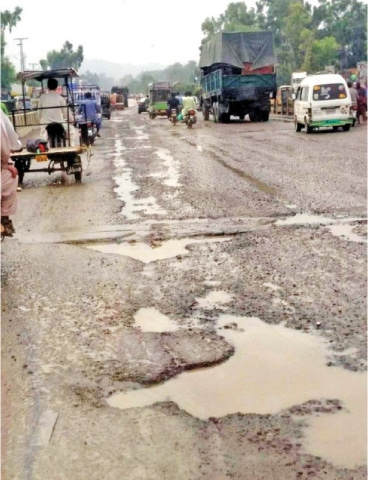


Image: 5f52a5cb8f728.jpg
Damage score: 90.67%
Decision threshold: 0.6578
PREDICTION: ROAD DAMAGE
---------------------------------------------


In [ ]:
import numpy as np
import tensorflow as tf
from PIL import Image
from google.colab import files
from IPython.display import display
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.metrics import roc_curve, accuracy_score, confusion_matrix
import io

# 1. Calculate a suitable threshold using validation data only
val_labels = []
val_scores = []

for images, labels in val_ds:
    scores = model.predict(images, verbose=0).reshape(-1)
    val_scores.extend(scores.tolist())
    val_labels.extend(labels.numpy().reshape(-1).astype(int).tolist())

val_labels = np.array(val_labels)
val_scores = np.array(val_scores)

fpr, tpr, thresholds = roc_curve(val_labels, val_scores)

# Choose threshold maximizing sensitivity + specificity - 1
valid = np.isfinite(thresholds)
best_index = np.argmax((tpr - fpr)[valid])
threshold = thresholds[valid][best_index]

val_preds = (val_scores >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(
    val_labels, val_preds, labels=[0, 1]
).ravel()

print("Validation-based threshold:", round(float(threshold), 4))
print("Validation accuracy:", round(accuracy_score(val_labels, val_preds), 4))
print("Validation specificity:", round(tn / (tn + fp), 4))
print("Validation damage recall:", round(tp / (tp + fn), 4))

# 2. Upload road images
print("\nUpload clear-road and damaged-road images to test:")
uploaded_images = files.upload()

# 3. Predict using the same preprocessing as training
for filename, file_bytes in uploaded_images.items():
    try:
        img = Image.open(io.BytesIO(file_bytes)).convert("RGB")
        display(img)

        resized = img.resize((224, 224))
        arr = np.array(resized, dtype=np.float32)
        batch = np.expand_dims(arr, axis=0)

        batch = preprocess_input(batch)
        score = float(model.predict(batch, verbose=0)[0][0])

        print("\nImage:", filename)
        print(f"Damage score: {score:.2%}")
        print(f"Decision threshold: {threshold:.4f}")

        if score >= threshold:
            print("PREDICTION: ROAD DAMAGE")
        else:
            print("PREDICTION: NO ROAD DAMAGE DETECTED")

        print("-" * 45)

    except Exception as e:
        print("Image processing error:", filename, str(e))

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Load the best saved model
model = tf.keras.models.load_model(
    "/content/drive/MyDrive/RoadGuardAI/roadguard_best.keras"
)

y_true = []
y_scores = []

# Predict on the untouched test dataset
for images, labels in test_ds:
    predictions = model.predict(images, verbose=0).reshape(-1)

    y_true.extend(labels.numpy().astype(int).tolist())
    y_scores.extend(predictions.tolist())

y_true = np.array(y_true)
y_scores = np.array(y_scores)

# Use 0.5 as the baseline threshold for this diagnostic
y_pred = (y_scores >= 0.5).astype(int)

print("Test ROC-AUC:", round(roc_auc_score(y_true, y_scores), 4))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["No Damage", "Damage"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Test ROC-AUC: 0.8422

Classification Report:
              precision    recall  f1-score   support

   No Damage     0.6209    0.7168    0.6654       971
      Damage     0.8649    0.8056    0.8342      2186

    accuracy                         0.7783      3157
   macro avg     0.7429    0.7612    0.7498      3157
weighted avg     0.7899    0.7783    0.7823      3157

Confusion Matrix:
[[ 696  275]
 [ 425 1761]]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

wrong_images = []
wrong_labels = []
wrong_scores = []

for images, labels in test_ds:
    scores = model.predict(images, verbose=0).reshape(-1)
    actual = labels.numpy().astype(int)

    predicted = (scores >= 0.5).astype(int)

    wrong_indices = np.where(predicted != actual)[0]

    for i in wrong_indices:
        wrong_images.append(images[i].numpy())
        wrong_labels.append(actual[i])
        wrong_scores.append(float(scores[i]))

print("Total incorrect predictions:", len(wrong_images))
print("Actual No Damage predicted as Damage:",
      sum(1 for y, s in zip(wrong_labels, wrong_scores)
          if y == 0 and s >= 0.5))

print("Actual Damage predicted as No Damage:",
      sum(1 for y, s in zip(wrong_labels, wrong_scores)
          if y == 1 and s < 0.5))

Total incorrect predictions: 700
Actual No Damage predicted as Damage: 275
Actual Damage predicted as No Damage: 425


Total incorrect predictions: 700


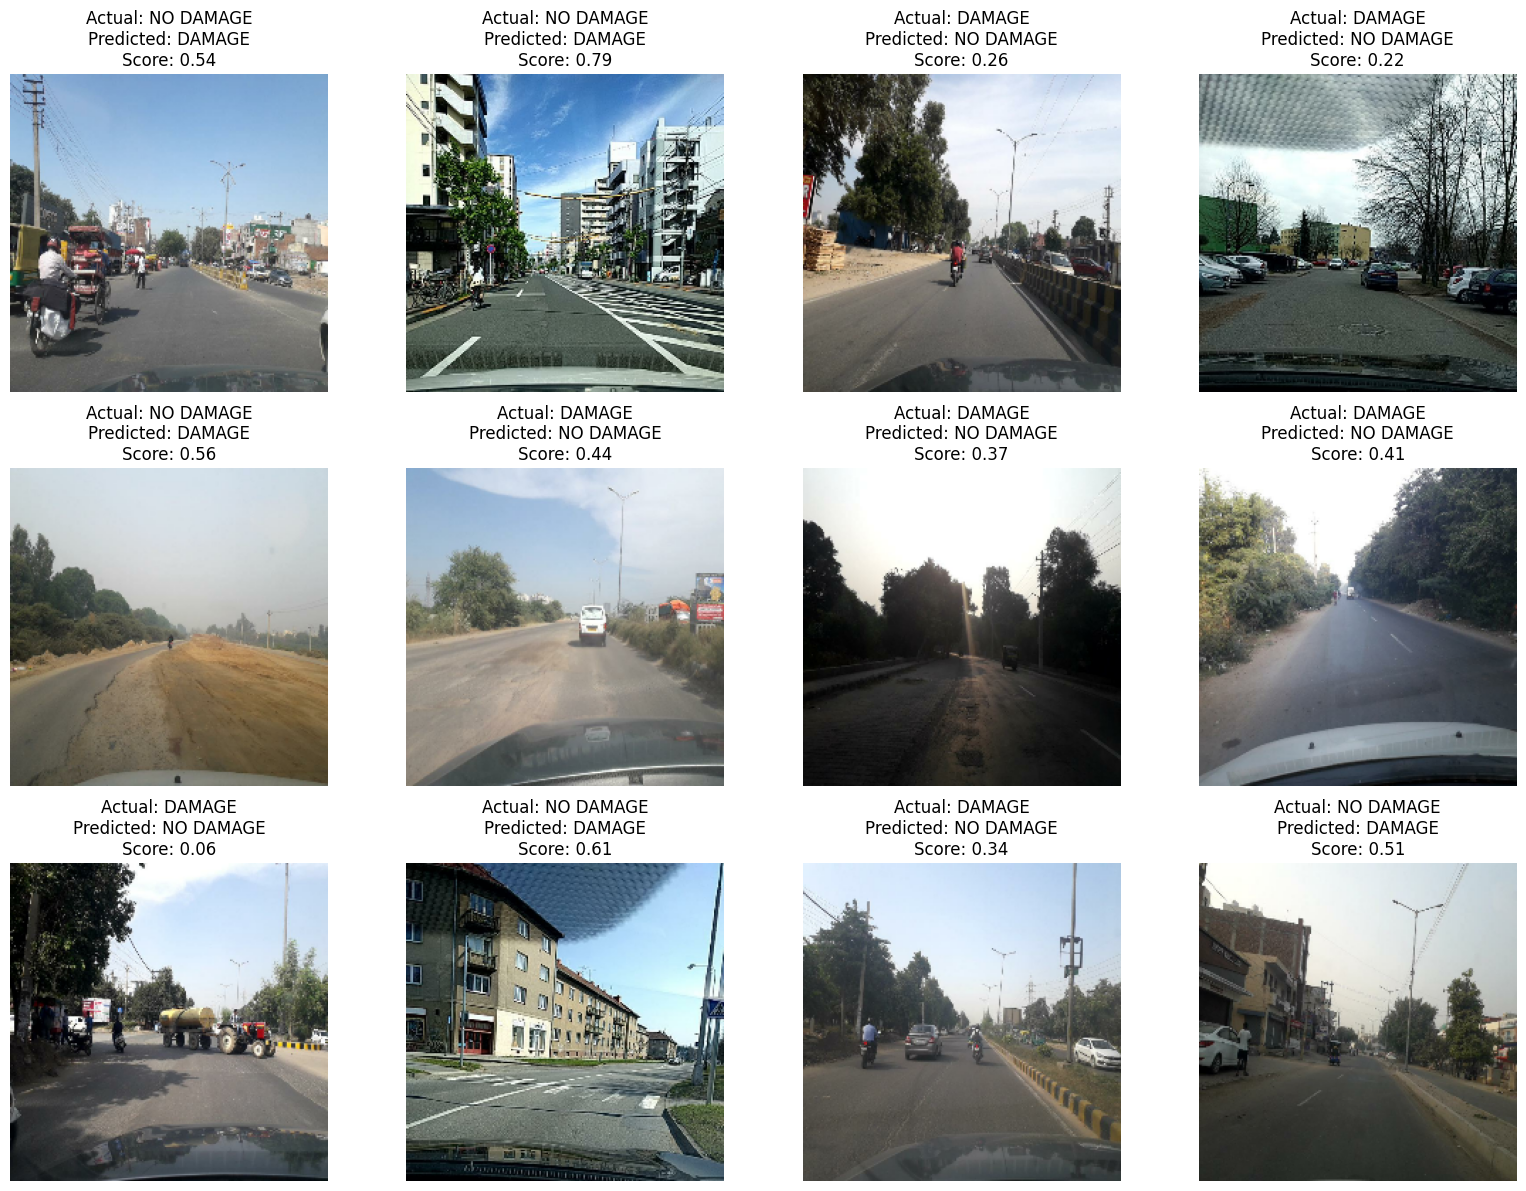

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Check that the previous cell created the incorrect predictions list
print("Total incorrect predictions:", len(wrong_images))

# Display the first 12 incorrectly classified images
n = min(12, len(wrong_images))
plt.figure(figsize=(16, 12))

for i in range(n):
    # Convert preprocessed image back to displayable RGB
    img = (wrong_images[i] + 1.0) * 127.5
    img = np.clip(img, 0, 255).astype("uint8")

    actual = "DAMAGE" if wrong_labels[i] == 1 else "NO DAMAGE"
    predicted = "DAMAGE" if wrong_scores[i] >= 0.5 else "NO DAMAGE"

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Score: {wrong_scores[i]:.2f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import random
import os

# Load the test dataset information
test_df = pd.read_csv("/content/drive/MyDrive/RoadGuardAI/test.csv")

print("Test dataset columns:")
print(test_df.columns.tolist())

print("\nFirst five rows:")
display(test_df.head())


Test dataset columns:
['image_path', 'label', 'country']

First five rows:


,image_path,label,country
0,/content/RoadGuardAI/dataset/train/India/India...,1,India
1,/content/RoadGuardAI/dataset/train/Japan/Japan...,1,Japan
2,/content/RoadGuardAI/dataset/train/Japan/Japan...,1,Japan
3,/content/RoadGuardAI/dataset/train/Japan/Japan...,1,Japan
4,/content/RoadGuardAI/dataset/train/Japan/Japan...,1,Japan


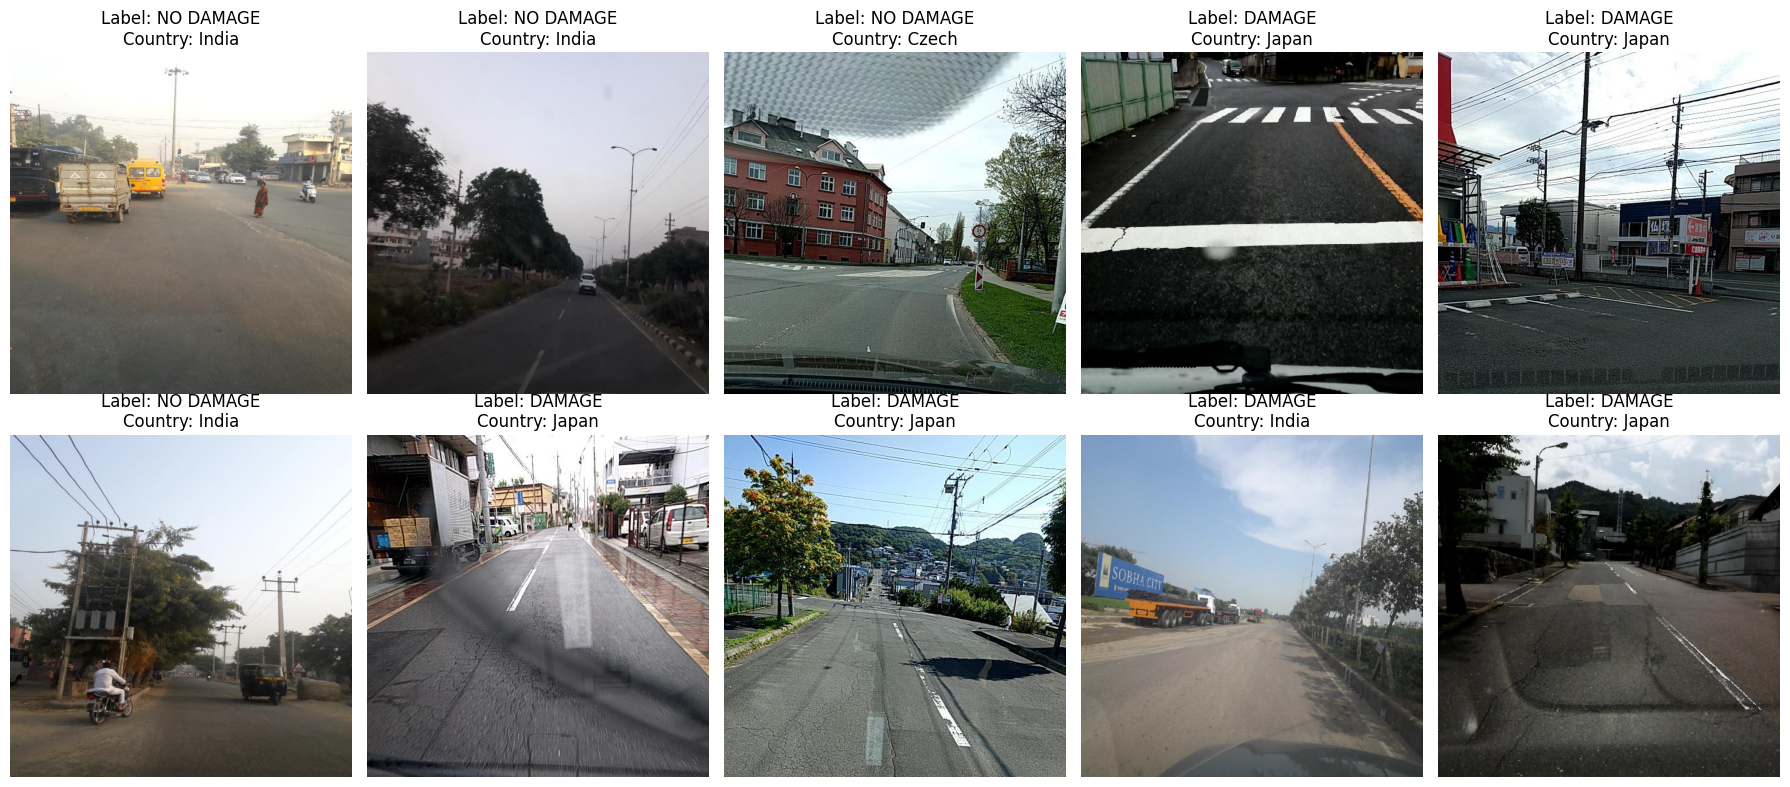

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import random
import os

# Load test dataset CSV
test_df = pd.read_csv(
    "/content/drive/MyDrive/RoadGuardAI/test.csv"
)

# Select 10 random rows
samples = test_df.sample(
    n=min(10, len(test_df)),
    random_state=42
)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.flatten()

for i, (_, row) in enumerate(samples.iterrows()):
    image_path = row["image_path"]
    label = int(row["label"])
    country = row["country"]

    try:
        img = Image.open(image_path).convert("RGB")

        axes[i].imshow(img)
        axes[i].set_title(
            f"Label: {'DAMAGE' if label == 1 else 'NO DAMAGE'}\n"
            f"Country: {country}"
        )
        axes[i].axis("off")

    except Exception as e:
        axes[i].text(
            0.5, 0.5,
            f"Image not found\n{os.path.basename(image_path)}",
            ha="center",
            va="center",
            wrap=True
        )
        axes[i].axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd

# Load all three dataset CSV files
train_df = pd.read_csv("/content/drive/MyDrive/RoadGuardAI/train.csv")
val_df = pd.read_csv("/content/drive/MyDrive/RoadGuardAI/val.csv")
test_df = pd.read_csv("/content/drive/MyDrive/RoadGuardAI/test.csv")

# Display label distribution
for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n--- {name} DATASET ---")
    print("Total images:", len(df))
    print("Label counts:")
    print(
        df["label"]
        .map({0: "NO DAMAGE", 1: "DAMAGE"})
        .value_counts()
    )

# Check image file availability
import os

for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    missing = sum(
        not os.path.exists(path)
        for path in df["image_path"]
    )
    print(f"{name}: Missing image files = {missing}")



--- TRAIN DATASET ---
Total images: 14728
Label counts:
label
DAMAGE       10198
NO DAMAGE     4530
Name: count, dtype: int64

--- VALIDATION DATASET ---
Total images: 3156
Label counts:
label
DAMAGE       2185
NO DAMAGE     971
Name: count, dtype: int64

--- TEST DATASET ---
Total images: 3157
Label counts:
label
DAMAGE       2186
NO DAMAGE     971
Name: count, dtype: int64
TRAIN: Missing image files = 0
VALIDATION: Missing image files = 0
TEST: Missing image files = 0


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

val_true = []
val_scores = []

for images, labels in val_ds:
    scores = model.predict(images, verbose=0).reshape(-1)
    val_true.extend(labels.numpy().astype(int))
    val_scores.extend(scores)

val_true = np.array(val_true)
val_scores = np.array(val_scores)

print("Validation threshold comparison:\n")

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    pred = (val_scores >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Accuracy: {accuracy_score(val_true, pred):.3f} | "
        f"Damage Precision: {precision_score(val_true, pred, zero_division=0):.3f} | "
        f"Damage Recall: {recall_score(val_true, pred, zero_division=0):.3f} | "
        f"Damage F1: {f1_score(val_true, pred, zero_division=0):.3f}"
    )

Validation threshold comparison:

Threshold: 0.30 | Accuracy: 0.739 | Damage Precision: 0.751 | Damage Recall: 0.931 | Damage F1: 0.831
Threshold: 0.40 | Accuracy: 0.756 | Damage Precision: 0.801 | Damage Recall: 0.862 | Damage F1: 0.830
Threshold: 0.50 | Accuracy: 0.746 | Damage Precision: 0.844 | Damage Recall: 0.778 | Damage F1: 0.809
Threshold: 0.60 | Accuracy: 0.742 | Damage Precision: 0.899 | Damage Recall: 0.706 | Damage F1: 0.791
Threshold: 0.70 | Accuracy: 0.713 | Damage Precision: 0.926 | Damage Recall: 0.636 | Damage F1: 0.754


In [ ]:
import os
import tensorflow as tf

backup_path = "/content/drive/MyDrive/RoadGuardAI/roadguard_before_finetuning.keras"

os.makedirs("/content/drive/MyDrive/RoadGuardAI", exist_ok=True)

model.save(backup_path)

print("Backup saved:", backup_path)

Backup saved: /content/drive/MyDrive/RoadGuardAI/roadguard_before_finetuning.keras


In [ ]:
print("Base model trainable:", base_model.trainable)
print("Total base-model layers:", len(base_model.layers))

for i, layer in enumerate(base_model.layers[-15:]):
    print(i - 15, layer.name, layer.trainable)

Base model trainable: False
Total base-model layers: 154
-15 block_15_depthwise_relu False
-14 block_15_project False
-13 block_15_project_BN False
-12 block_15_add False
-11 block_16_expand False
-10 block_16_expand_BN False
-9 block_16_expand_relu False
-8 block_16_depthwise False
-7 block_16_depthwise_BN False
-6 block_16_depthwise_relu False
-5 block_16_project False
-4 block_16_project_BN False
-3 Conv_1 False
-2 Conv_1_bn False
-1 out_relu False


In [ ]:
print("base_model exists:", "base_model" in globals())
print("model exists:", "model" in globals())
print("val_ds exists:", "val_ds" in globals())

base_model exists: True
model exists: True
val_ds exists: True


In [ ]:
import tensorflow as tf

# Unfreeze the base model
base_model.trainable = True

# Train only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a very small learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("Fine-tuning setup complete.")
print("Trainable base-model layers:",
      sum(layer.trainable for layer in base_model.layers))

Fine-tuning setup complete.
Trainable base-model layers: 19


In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/drive/MyDrive/RoadGuardAI/roadguard_finetuned_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks
)

Epoch 1/5
461/461 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.7649 - auc: 0.8243 - loss: 0.4725 - precision: 0.8296 - recall: 0.8267
Epoch 1: val_loss improved from None to 0.46854, saving model to /content/drive/MyDrive/RoadGuardAI/roadguard_finetuned_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/RoadGuardAI/roadguard_finetuned_best.keras
461/461 ━━━━━━━━━━━━━━━━━━━━ 65s 119ms/step - accuracy: 0.7698 - auc: 0.8294 - loss: 0.4616 - precision: 0.8278 - recall: 0.8429 - val_accuracy: 0.7573 - val_auc: 0.8191 - val_loss: 0.4685 - val_precision: 0.8054 - val_recall: 0.8563
Epoch 2/5
460/461 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.7656 - auc: 0.8313 - loss: 0.4622 - precision: 0.8116 - recall: 0.8560
Epoch 2: val_loss improved from 0.46854 to 0.46799, saving model to /content/drive/MyDrive/RoadGuardAI/roadguard_finetuned_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/RoadGuardAI/roadguard_finetuned_best.keras
461/461 ━━━━━━━━━━━━━━━━━

In [ ]:
import tensorflow as tf
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

original_path = "/content/drive/MyDrive/RoadGuardAI/roadguard_before_finetuning.keras"
finetuned_path = "/content/drive/MyDrive/RoadGuardAI/roadguard_finetuned_best.keras"

original_model = tf.keras.models.load_model(original_path)
finetuned_model = tf.keras.models.load_model(finetuned_path)

y_true = []
original_scores = []
finetuned_scores = []

for images, labels in val_ds:
    original_scores.extend(
        original_model.predict(images, verbose=0).reshape(-1)
    )
    finetuned_scores.extend(
        finetuned_model.predict(images, verbose=0).reshape(-1)
    )
    y_true.extend(labels.numpy().astype(int))

y_true = np.array(y_true)

def show_metrics(name, scores):
    predictions = (scores >= 0.5).astype(int)

    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y_true, predictions), 4))
    print("Precision:", round(precision_score(y_true, predictions, zero_division=0), 4))
    print("Recall:", round(recall_score(y_true, predictions, zero_division=0), 4))
    print("F1-score:", round(f1_score(y_true, predictions, zero_division=0), 4))
    print("ROC-AUC:", round(roc_auc_score(y_true, scores), 4))

show_metrics("ORIGINAL MODEL", np.array(original_scores))
show_metrics("FINE-TUNED MODEL", np.array(finetuned_scores))



ORIGINAL MODEL
Accuracy: 0.7462
Precision: 0.8436
Recall: 0.7776
F1-score: 0.8092
ROC-AUC: 0.8186

FINE-TUNED MODEL
Accuracy: 0.7617
Precision: 0.8103
Recall: 0.8563
F1-score: 0.8327
ROC-AUC: 0.8213


In [ ]:
import tensorflow as tf
import os

source = "/content/drive/MyDrive/RoadGuardAI/roadguard_finetuned_best.keras"
final_path = "/content/drive/MyDrive/RoadGuardAI/roadguard_final.keras"

best_model = tf.keras.models.load_model(source)
best_model.save(final_path)

print("Final model saved:", final_path)
print("File size (MB):", round(os.path.getsize(final_path) / (1024 * 1024), 2))

Final model saved: /content/drive/MyDrive/RoadGuardAI/roadguard_final.keras
File size (MB): 9.18


In [ ]:
import tensorflow as tf
import numpy as np
import os

model_path = "/content/drive/MyDrive/RoadGuardAI/roadguard_final.keras"

# Load final model
model = tf.keras.models.load_model(model_path)

# Test whether the model can perform inference
dummy_image = np.zeros((1, 224, 224, 3), dtype=np.float32)
prediction = model.predict(dummy_image, verbose=0)

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Test inference score:", float(prediction[0][0]))
print("Model size (MB):", round(os.path.getsize(model_path) / (1024 * 1024), 2))

Model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)
Test inference score: 0.37595880031585693
Model size (MB): 9.18


In [ ]:
from google.colab import files
import shutil

files.download("/content/RoadGuardAI/roadguard_best.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import zipfile

project = "/content/RoadGuardAI/submission_files"
os.makedirs(project, exist_ok=True)

files_to_create = {
    "app.py": '''
import os
import numpy as np
import tensorflow as tf
from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import gradio as gr

MODEL_PATH = os.environ.get("MODEL_PATH", "roadguard_best.keras")
model = tf.keras.models.load_model(MODEL_PATH)

# Temporary decision threshold; validate before final submission.
THRESHOLD = 0.715
MARGIN = 0.10

def predict_road(image):
    if image is None:
        return {"Please upload a road image": 1.0}

    image = image.convert("RGB").resize((224, 224))
    arr = np.array(image, dtype=np.float32)
    batch = preprocess_input(np.expand_dims(arr, axis=0))
    score = float(model.predict(batch, verbose=0)[0][0])

    if score >= THRESHOLD + MARGIN:
        label = "ROAD DAMAGE"
    elif score <= THRESHOLD - MARGIN:
        label = "NO ROAD DAMAGE DETECTED"
    else:
        label = "UNCERTAIN - PLEASE REVIEW"

    return {
        label: 1.0,
        f"Model damage score: {score:.2%}": 0.0
    }

demo = gr.Interface(
    fn=predict_road,
    inputs=gr.Image(type="pil", label="Upload a road image"),
    outputs=gr.Label(label="RoadGuard AI Result"),
    title="RoadGuard AI",
    description="Deep learning road damage classification demo. Results may be incorrect; please review uncertain predictions."
)

if __name__ == "__main__":
    demo.launch()
''',
    "requirements.txt": '''
tensorflow
gradio
pillow
numpy
''',
    "README.md": '''
# RoadGuard AI

RoadGuard AI is a deep-learning road-image classification project using MobileNetV2 and a subset of the RDD2020 dataset.

## Classes
- ROAD DAMAGE
- NO ROAD DAMAGE DETECTED
- UNCERTAIN - PLEASE REVIEW

## Model
Place `roadguard_best.keras` next to `app.py`, or set the `MODEL_PATH` environment variable to its location.

## Run locally
Install dependencies:

    pip install -r requirements.txt

Start the app:

    python app.py

## Important
The model is an experimental binary classifier, not a road-safety authority. Its outputs may be incorrect. The decision threshold is provisional and should be checked against validation data before deployment.

Dataset usage must comply with the RDD2020 dataset licence and terms.
'''
}

for name, content in files_to_create.items():
    with open(os.path.join(project, name), "w", encoding="utf-8") as f:
        f.write(content.strip() + "\n")

zip_path = "/content/RoadGuardAI_submission_files.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for name in files_to_create:
        z.write(os.path.join(project, name), arcname=name)

print("Created files:")
for name in files_to_create:
    print("-", name)
print("\nZIP:", zip_path)

from google.colab import files
files.download(zip_path)

Created files:
- app.py
- requirements.txt
- README.md

ZIP: /content/RoadGuardAI_submission_files.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

folder = "/content/RoadGuardAI"

files_to_check = [
    "/content/RoadGuardAI/app.py",
    "/content/RoadGuardAI/requirements.txt",
    "/content/RoadGuardAI/README.md",
    "/content/drive/MyDrive/RoadGuardAI/roadguard_final.keras"
]

for file in files_to_check:
    if os.path.exists(file):
        print("FOUND:", file)
    else:
        print("MISSING:", file)

MISSING: /content/RoadGuardAI/app.py
MISSING: /content/RoadGuardAI/requirements.txt
MISSING: /content/RoadGuardAI/README.md
FOUND: /content/drive/MyDrive/RoadGuardAI/roadguard_final.keras


In [ ]:
import os
import shutil
import zipfile

folder = "/content/RoadGuardAI"
os.makedirs(folder, exist_ok=True)

# Copy final model from Google Drive
shutil.copy2(
    "/content/drive/MyDrive/RoadGuardAI/roadguard_final.keras",
    f"{folder}/roadguard_final.keras"
)

# 1. Create app.py
app_code = '''
import os
import numpy as np
import tensorflow as tf
import gradio as gr
from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

MODEL_PATH = os.environ.get("MODEL_PATH", "roadguard_final.keras")
model = tf.keras.models.load_model(MODEL_PATH)

THRESHOLD = 0.50

def predict_road(image):
    if image is None:
        return {"Please upload a road image": 1.0}

    image = image.convert("RGB").resize((224, 224))
    arr = np.asarray(image, dtype=np.float32)
    batch = preprocess_input(np.expand_dims(arr, axis=0))
    score = float(model.predict(batch, verbose=0)[0][0])

    label = "ROAD DAMAGE" if score >= THRESHOLD else "NO ROAD DAMAGE DETECTED"

    return {
        label: 1.0,
        f"Model damage score (not a calibrated probability): {score:.2%}": 0.0
    }

demo = gr.Interface(
    fn=predict_road,
    inputs=gr.Image(type="pil", label="Upload a road image"),
    outputs=gr.Label(label="RoadGuard AI Result"),
    title="RoadGuard AI",
    description="Upload a road image for classification. Predictions may be incorrect."
)

if __name__ == "__main__":
    demo.launch()
'''

with open(f"{folder}/app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

# 2. Create requirements.txt
requirements = """tensorflow
gradio
pillow
numpy
"""

with open(f"{folder}/requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements)

# 3. Create README.md
readme = """# RoadGuard AI

A deep-learning prototype that classifies road images as ROAD DAMAGE or
NO ROAD DAMAGE DETECTED using a fine-tuned MobileNetV2 model.

## Run locally
1. Install the required packages using:
   pip install -r requirements.txt
2. Keep roadguard_final.keras in the same folder as app.py.
3. Run:
   python app.py

## Technical details
- Input image: RGB, resized to 224x224
- Preprocessing: MobileNetV2 preprocess_input
- Dataset: RDD2020 subset
- Output: binary classification score

## Limitations
This is an academic prototype. Predictions can be wrong and require human review.
NO ROAD DAMAGE DETECTED does not guarantee a road is damage-free.
The displayed score is not a calibrated probability.
"""

with open(f"{folder}/README.md", "w", encoding="utf-8") as f:
    f.write(readme)

# 4. Package all files into one ZIP
zip_path = "/content/RoadGuardAI_submission_files.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in [
        "app.py",
        "requirements.txt",
        "README.md",
        "roadguard_final.keras"
    ]:
        z.write(f"{folder}/{filename}", arcname=filename)

# 5. Verify files
for filename in [
    "app.py",
    "requirements.txt",
    "README.md",
    "roadguard_final.keras"
]:
    print("FOUND:", filename)

print("\nZIP created:", zip_path)

FOUND: app.py
FOUND: requirements.txt
FOUND: README.md
FOUND: roadguard_final.keras

ZIP created: /content/RoadGuardAI_submission_files.zip


In [ ]:
from google.colab import files
files.download("/content/RoadGuardAI_submission_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>